[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/abpandey-dev/learn-python-from-scratch-to-advanced/blob/main/notebooks/04-machine-learning/04_evaluation.ipynb)

*Machine Learning from Scratch · Notebook 4 of 10*

# Model Evaluation & Validation

Measuring a model honestly: the confusion matrix, precision, recall, F1, ROC and PR curves, MCC and kappa, choosing thresholds, and cross-validation strategies.

### 👩‍🏫 From your teacher

**The picture to keep in your head:** Accuracy can lie. A model that always says 'no fraud' is 99.9% accurate, and useless.

**What interviewers really test here:** Precision vs recall trade-offs, ROC vs PR, and cross-validation done right.

### How to use this notebook

1. **Run the setup cell** just below.
2. **Read each lesson slowly.** Work the numbers on paper before reading on.
3. **Run and then change the examples.** Breaking code on purpose is how you learn.
4. **Try each practice question before opening an answer.** If you're stuck, open one hint at a time.
5. **Say your interview answers out loud.** Knowing something and explaining it are different skills.

### Your roadmap

- [ ] 1. The confusion matrix *(Basics)*
- [ ] 2. A full worked example: screening 1,000 people *(Basics)*
- [ ] 3. Precision, recall and F1 *(Core)*
- [ ] 4. ROC and precision–recall curves *(Core)*
- [ ] 5. Why F1 uses the harmonic mean, and macro vs weighted *(Core)*
- [ ] 6. ROC and PR curves, by hand *(Core)*
- [ ] 7. Cross-validation done right *(Advanced)*
- [ ] 8. Which metric for which problem? *(Advanced)*
- [ ] 9. Choosing a validation strategy *(Advanced)*
- [ ] 20 practice questions
- [ ] Interview questions, out loud

In [1]:
# ▶ Run this cell first. It prepares the notebook; you don't need to read it.
import contextlib, copy, io, math, sys
import numpy as np, matplotlib.pyplot as plt
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
PLAIN = True

class ListNode:
    def __init__(self, val=0, next=None):
        self.val, self.next = val, next

class TreeNode:
    def __init__(self, val=0, left=None, right=None):
        self.val, self.left, self.right = val, left, right

def mk_list(vals, pos=-1):
    dummy = cur = ListNode()
    nodes = []
    for v in vals:
        cur.next = ListNode(v)
        cur = cur.next
        nodes.append(cur)
    if pos >= 0 and nodes:
        nodes[-1].next = nodes[pos]
    return dummy.next

def list_arr(head):
    out, seen = [], set()
    while head and id(head) not in seen:
        seen.add(id(head))
        out.append(head.val)
        head = head.next
    return out

def mk_tree(vals):
    if not vals or vals[0] is None:
        return None
    root = TreeNode(vals[0])
    queue, i = [root], 1
    while queue and i < len(vals):
        node = queue.pop(0)
        for side in ("left", "right"):
            if i < len(vals) and vals[i] is not None:
                child = TreeNode(vals[i])
                setattr(node, side, child)
                queue.append(child)
            i += 1
    return root

def tree_arr(root):
    out, queue = [], [root]
    while queue:
        node = queue.pop(0)
        if node:
            out.append(node.val)
            queue += [node.left, node.right]
        else:
            out.append(None)
    while out and out[-1] is None:
        out.pop()
    return out

def find(root, val):
    if not root or root.val == val:
        return root
    return find(root.left, val) or find(root.right, val)

ListNode.__repr__ = lambda self: f"ListNode{list_arr(self)}"
TreeNode.__repr__ = lambda self: f"TreeNode{tree_arr(self)}"

def plain(x, digits=4):
    """NumPy / pandas results as plain Python values, so they compare with a test's expected answer."""
    np = sys.modules.get("numpy")
    pd = sys.modules.get("pandas")
    if pd is not None:
        if isinstance(x, pd.DataFrame):
            return {str(c): plain(x[c].tolist(), digits) for c in x.columns}
        if isinstance(x, pd.Series):
            return {plain(k, digits): plain(v, digits) for k, v in x.items()}
        if isinstance(x, pd.Index):
            return plain(x.tolist(), digits)
        if x is pd.NaT:
            return None
        if isinstance(x, pd.Timestamp):
            return str(x.date()) if x == x.normalize() else str(x)
    if np is not None:
        if isinstance(x, np.ndarray):
            return plain(x.tolist(), digits)
        if isinstance(x, np.generic):
            return plain(x.item(), digits)
    if isinstance(x, float):
        return None if x != x else round(x, digits) + 0.0
    if isinstance(x, list):
        return [plain(v, digits) for v in x]
    if isinstance(x, tuple):
        return tuple(plain(v, digits) for v in x)
    if isinstance(x, dict):
        return {plain(k, digits): plain(v, digits) for k, v in x.items()}
    if isinstance(x, (set, frozenset)):
        return {plain(v, digits) for v in x}
    return x


def check(fn, tests, plain_compare=None, listify=False, design=False, prep=None, post=None,
          norm=None, verify=None, runner=None, inplace=None):
    """Run your code against the tests and show which pass."""
    use_plain = PLAIN if plain_compare is None else plain_compare
    passed, problems = 0, []
    for args, want in tests:
        try:
            a = copy.deepcopy(args)
            if design:
                obj = fn(*a[0])
                got = [getattr(obj, m)(*p) for m, p in a[1]]
            elif runner is not None:
                got = runner(fn, a)
            else:
                if prep is not None:
                    a = prep(a)
                with contextlib.redirect_stdout(io.StringIO()):
                    got = fn(*a)
                if inplace is not None:
                    got = a[inplace]
                if listify:
                    got = list(got)
                if post is not None:
                    got = post(got)
            if verify is not None:
                ok = bool(verify(copy.deepcopy(args), got))
            elif norm is not None:
                ok = norm(copy.deepcopy(got)) == norm(copy.deepcopy(want))
            else:
                ok = (plain(got), plain(want)) if use_plain else (got, want)
                ok = ok[0] == ok[1]
            ok = ok if isinstance(ok, bool) else False
        except Exception as e:  # your code raised an error: report it, don't stop the notebook
            ok, got = False, f"{type(e).__name__}: {e}"
        passed += ok
        if not ok:
            problems.append((args, want, got))
    plt.close("all")
    if passed == len(tests):
        print(f"✅ All {len(tests)} tests passed. Well done! Now compare with the answers below.")
    else:
        print(f"❌ {passed}/{len(tests)} tests passed. First one to fix:")
        args, want, got = problems[0]
        print("   input:   ", repr(args)[:300])
        print("   expected:", repr(want)[:300])
        print("   you got: ", repr(got)[:300])
    return None

print("Ready! Scroll down and start learning.")

Ready! Scroll down and start learning.


---
# Part 1: The theory in one place

Read this once for the big picture. It's fine if it doesn't all stick yet: the lessons will make it concrete, and you can come back to revise.

### Classification metrics

| Metric | Formula | Use when |
| --- | --- | --- |
| Accuracy | (TP + TN)/n | balanced classes, equal costs |
| Precision | TP/(TP + FP) | false positives are costly (spam filter) |
| Recall / TPR | TP/(TP + FN) | misses are costly (disease, fraud) |
| Specificity / TNR | TN/(TN + FP) | medical screening (with sensitivity) |
| F1 / Fβ | (1 + β²)PR/(β²P + R) | β &gt; 1 favours recall |
| Balanced accuracy | mean per-class recall | imbalanced data |
| MCC | (TP·TN − FP·FN)/√(…) | imbalanced binary; uses all four cells |
| Cohen's κ | (p\_o − p\_e)/(1 − p\_e) | agreement corrected for chance |
| ROC AUC | P(score₊ &gt; score₋) | ranking quality, threshold-free |
| Average precision | Σ(Rₙ − Rₙ₋₁)Pₙ | rare positives |
| Log-loss, Brier | −mean log p, mean (p − y)² | probability quality / calibration |

### Validation strategies

- **Hold-out**: one train/test split — simple, high variance on small data.
- **k-fold CV**: k estimates, report mean ± std; k = 5 or 10 typical.
- **Stratified** folds for classification; **grouped** folds for repeated subjects; **time-series** splits for temporal data.
- **Nested CV**: inner loop tunes hyper-parameters, outer loop estimates performance — avoids optimistic bias from tuning on the evaluation folds.
- The test set is used once; reusing it for decisions turns it into a validation set.

### Diagnosing models

| Symptom | Diagnosis | Remedies |
| --- | --- | --- |
| Train and validation error both high | underfitting (bias) | more features, more complex model, less regularisation |
| Train error low, validation high | overfitting (variance) | more data, regularisation, simpler model, ensembling, early stopping |
| Validation suspiciously high | leakage | audit features and preprocessing order |
| Good offline, bad in production | data drift / train-serve skew | monitor inputs, retrain, same pipeline in both |



Learning curves (score vs training size) show whether more data would help; validation curves (score vs a hyper-parameter) show the bias–variance trade-off.

---
# Part 2: Lessons, step by step

## Lesson 1: The confusion matrix

*Level: Basics*

Accuracy hides *which* mistakes a model makes. The **confusion matrix** counts all four outcomes:



|   | Predicted no | Predicted yes |
| --- | --- | --- |
| Actually no | **TN** true negative | **FP** false positive (false alarm) |
| Actually yes | **FN** false negative (missed!) | **TP** true positive |



Which mistake is worse depends on the problem. Missing a cancer (FN) is far worse than an extra test (FP). Flagging a good email as spam (FP) is worse than letting one spam through.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

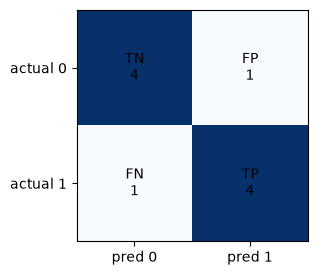

In [2]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve
Y = np.array([1, 0, 1, 1, 0, 1, 0, 0, 1, 0])
S = np.array([0.9, 0.1, 0.4, 0.8, 0.3, 0.7, 0.6, 0.2, 0.65, 0.35])


def confusion_demo():
    y_pred = (S >= 0.5).astype(int)
    cm = confusion_matrix(Y, y_pred)
    fig, ax = plt.subplots(figsize=(3.4, 3))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, ["TN", "FP", "FN", "TP"][2 * i + j] + f"\n{cm[i, j]}", ha="center", va="center")
    ax.set_xticks([0, 1], ["pred 0", "pred 1"])
    ax.set_yticks([0, 1], ["actual 0", "actual 1"])


confusion_demo()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q9](#q9). Try one now, or carry on and do them in Part 3.

## Lesson 2: A full worked example: screening 1,000 people

*Level: Basics*

20 of 1,000 people have a disease. A test gives these results:



|   | Predicted healthy | Predicted sick | Total |
| --- | --- | --- | --- |
| Actually healthy | TN = 931 | FP = 49 | 980 |
| Actually sick | FN = 2 | TP = 18 | 20 |



| Metric | Calculation | Value | In plain words |
| --- | --- | --- | --- |
| Accuracy | (18 + 931) / 1000 | 0.949 | right 94.9% of the time |
| Recall | 18 / 20 | 0.90 | finds 90% of sick people |
| Precision | 18 / 67 | 0.269 | only 27% of alarms are real |
| Specificity | 931 / 980 | 0.95 | clears 95% of healthy people |
| F1 | 36 / (36 + 49 + 2) | 0.414 | combined score |



#### The surprise



A useless test that says "healthy" to everyone scores **98% accuracy**, better than this real test, while finding nobody. Accuracy alone is misleading here.



The test is also fine for screening despite its low precision: most people who test positive are healthy, but a follow-up test can sort them out. A missed patient (FN) is what you must avoid.



**Remember:** precision has "predicted positive" on the bottom; recall has "actually positive" on the bottom.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [3]:
def screening_numbers():
    tp, fn, fp, tn = 18, 2, 49, 931
    accuracy = (tp + tn) / 1000
    recall = tp / (tp + fn)
    precision = tp / (tp + fp)
    specificity = tn / (tn + fp)
    f1 = 2 * tp / (2 * tp + fp + fn)
    useless_test_accuracy = 980 / 1000
    useless_test_recall = 0 / 20


screening_numbers()

**✏️ Your turn:** you now have what you need for [Q1](#q1), [Q2](#q2), [Q3](#q3), [Q4](#q4), [Q5](#q5). Try one now, or carry on and do them in Part 3.

## Lesson 3: Precision, recall and F1

*Level: Core*

| Metric | Formula | Question it answers |
| --- | --- | --- |
| **Precision** | TP / (TP + FP) | When the model says yes, how often is it right? |
| **Recall** (sensitivity) | TP / (TP + FN) | Of all real yeses, how many did it find? |
| Specificity | TN / (TN + FP) | Of all real nos, how many did it clear? |
| **F1** | 2PR / (P + R) | one number balancing both |
| Balanced accuracy | mean recall per class | fair accuracy for imbalanced data |
| MCC | correlation of predictions with truth | robust single score, −1 … 1 |



For many classes, compute per-class scores and average them: **macro** (each class equal) or **weighted** (by class size).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

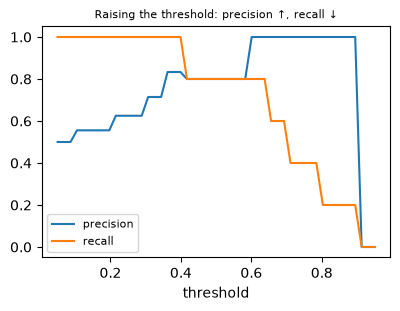

In [4]:
Y = np.array([1, 0, 1, 1, 0, 1, 0, 0, 1, 0])
S = np.array([0.9, 0.1, 0.4, 0.8, 0.3, 0.7, 0.6, 0.2, 0.65, 0.35])


def tradeoff_demo():
    thresholds = np.linspace(0.05, 0.95, 50)
    precision, recall = [], []
    for t in thresholds:
        pred = S >= t
        tp = (pred & (Y == 1)).sum()
        precision.append(tp / max(pred.sum(), 1))
        recall.append(tp / (Y == 1).sum())
    fig, ax = plt.subplots(figsize=(4.5, 3))
    ax.plot(thresholds, precision, label="precision")
    ax.plot(thresholds, recall, label="recall")
    ax.set_xlabel("threshold")
    ax.legend(fontsize=8)
    ax.set_title("Raising the threshold: precision ↑, recall ↓", fontsize=8)


tradeoff_demo()

**✏️ Your turn:** you now have what you need for [Q2](#q2), [Q3](#q3), [Q4](#q4), [Q5](#q5), [Q6](#q6), [Q10](#q10), [Q11](#q11), [Q14](#q14), [Q15](#q15). Try one now, or carry on and do them in Part 3.

## Lesson 4: ROC and precision–recall curves

*Level: Core*

A model outputs scores; the threshold turns them into decisions. Instead of judging one threshold, curves judge them all:




- **ROC curve**: true positive rate vs false positive rate. **ROC AUC** = chance a random positive is scored above a random negative (0.5 = coin flip, 1 = perfect).
- **Precision–recall curve** and its area, **average precision**: better than ROC when positives are rare (fraud, disease), because it ignores the huge pile of easy negatives.



Pick the final threshold from the curve based on what mistakes cost, e.g. the one maximising F1 or meeting "recall ≥ 95%". **Brier score** and log-loss check whether the probabilities themselves are trustworthy (calibration).

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

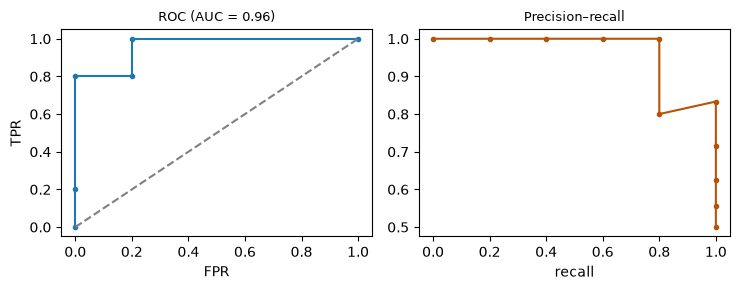

In [5]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve
Y = np.array([1, 0, 1, 1, 0, 1, 0, 0, 1, 0])
S = np.array([0.9, 0.1, 0.4, 0.8, 0.3, 0.7, 0.6, 0.2, 0.65, 0.35])


def roc_pr_curves():
    fpr, tpr, _ = roc_curve(Y, S)
    prec, rec, _ = precision_recall_curve(Y, S)
    auc = roc_auc_score(Y, S)
    fig, (left, right) = plt.subplots(1, 2, figsize=(7.5, 3))
    left.plot(fpr, tpr, marker="o", markersize=3)
    left.plot([0, 1], [0, 1], "--", color="gray")
    left.set_title(f"ROC (AUC = {auc:.2f})", fontsize=9)
    left.set_xlabel("FPR")
    left.set_ylabel("TPR")
    right.plot(rec, prec, marker="o", markersize=3, color="#b45309")
    right.set_title("Precision–recall", fontsize=9)
    right.set_xlabel("recall")
    fig.tight_layout()


roc_pr_curves()

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q13](#q13), [Q19](#q19), [Q20](#q20), [Q7](#q7), [Q8](#q8). Try one now, or carry on and do them in Part 3.

## Lesson 5: Why F1 uses the harmonic mean, and macro vs weighted

*Level: Core*

#### The harmonic mean punishes imbalance



A model flags only one sure case: precision 1.0, recall 0.01.



- Ordinary average: (1 + 0.01) / 2 = 0.505, which looks acceptable.
- F1: 2 × 1 × 0.01 / 1.01 = **0.020**, which is honest.



F1 is only high when both are high. If one matters more, use Fβ: β &gt; 1 favours recall.



#### Many classes: worked example



90 rows of class A and 10 of class B. Of the A rows, 85 are right and 5 are called B. Of the B rows, 4 are right and 6 are called A. This gives F1(A) = 0.939 and F1(B) = 0.421.



| Average | How | Result | Use when |
| --- | --- | --- | --- |
| Macro | plain mean of class scores | 0.680 | every class matters equally |
| Weighted | mean weighted by class size | 0.887 | larger classes matter more |
| Micro | pool all counts (equals accuracy here) | 0.890 | each row matters equally |



The weak class B is obvious in the macro score and hidden in the other two. Always look at per-class scores too.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

In [6]:
def averaging_compare():
    from sklearn.metrics import f1_score
    y = np.array(["A"] * 90 + ["B"] * 10)
    pred = np.array(["A"] * 85 + ["B"] * 5 + ["A"] * 6 + ["B"] * 4)
    per_class = f1_score(y, pred, average=None)
    macro = f1_score(y, pred, average="macro")
    weighted = f1_score(y, pred, average="weighted")
    micro = f1_score(y, pred, average="micro")


averaging_compare()

**✏️ Your turn:** you now have what you need for [Q10](#q10), [Q11](#q11), [Q4](#q4). Try one now, or carry on and do them in Part 3.

## Lesson 6: ROC and PR curves, by hand

*Level: Core*

Six rows sorted by score. Lower the threshold one row at a time:



| Row's score | True label | TP | FP | TPR (recall) | FPR | Precision |
| --- | --- | --- | --- | --- | --- | --- |
| 0.9 | 1 | 1 | 0 | 0.33 | 0 | 1.00 |
| 0.8 | 1 | 2 | 0 | 0.67 | 0 | 1.00 |
| 0.7 | 0 | 2 | 1 | 0.67 | 0.33 | 0.67 |
| 0.6 | 1 | 3 | 1 | 1.00 | 0.33 | 0.75 |
| 0.4 | 0 | 3 | 2 | 1.00 | 0.67 | 0.60 |
| 0.2 | 0 | 3 | 3 | 1.00 | 1.00 | 0.50 |



A positive row moves the ROC curve up; a negative row moves it right.



#### ROC AUC by counting pairs



Compare each of the 3 positives with each of the 3 negatives (0.7, 0.4, 0.2). 0.9 beats 3, 0.8 beats 3, and 0.6 beats 2. So AUC = 8 / 9 = **0.889**: a random positive outranks a random negative 89% of the time.



#### Average precision



Add precision each time recall rises by 1/3: (1/3)(1.00) + (1/3)(1.00) + (1/3)(0.75) = **0.917**.



**Which to use?** With rare positives, ROC AUC can look great while most alerts are false. Prefer PR-AUC there. Note that a random model's PR-AUC equals the share of positives, not 0.5.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

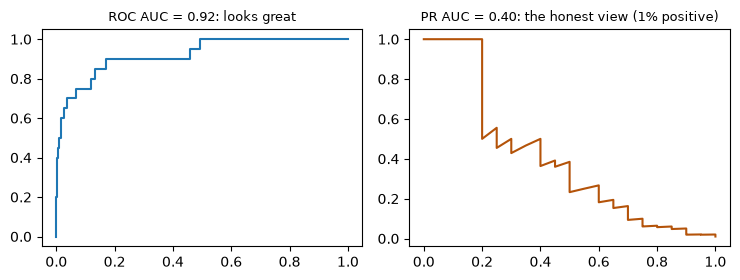

In [7]:
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, precision_recall_curve


def rare_positives():
    from sklearn.metrics import average_precision_score
    rng = np.random.default_rng(0)
    y = np.r_[np.zeros(1980, dtype=int), np.ones(20, dtype=int)]
    scores = np.r_[rng.normal(0, 1, 1980), rng.normal(2, 1, 20)]
    fpr, tpr, _ = roc_curve(y, scores)
    prec, rec, _ = precision_recall_curve(y, scores)
    auc = roc_auc_score(y, scores)
    ap = average_precision_score(y, scores)
    fig, (left, right) = plt.subplots(1, 2, figsize=(7.5, 2.9))
    left.plot(fpr, tpr)
    left.set_title(f"ROC AUC = {auc:.2f}: looks great", fontsize=9)
    right.plot(rec, prec, color="#b45309")
    right.set_title(f"PR AUC = {ap:.2f}: the honest view (1% positive)", fontsize=9)
    fig.tight_layout()


rare_positives()

**✏️ Your turn:** you now have what you need for [Q12](#q12), [Q13](#q13), [Q19](#q19). Try one now, or carry on and do them in Part 3.

## Lesson 7: Cross-validation done right

*Level: Advanced*

One train/test split is noisy — you might get lucky. **k-fold cross-validation** splits the data into k parts, trains on k − 1 and tests on the remaining one, k times, then averages. Every row is tested exactly once.



| Splitter | Use when |
| --- | --- |
| KFold | regression, plenty of data |
| StratifiedKFold | classification — keeps class shares in every fold |
| GroupKFold | several rows per patient/user — keep each group in one fold |
| TimeSeriesSplit | time-ordered data — always test on the future |
| LeaveOneOut | tiny datasets |



Tune hyper-parameters with cross-validation on the training set; keep the test set for one final check.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

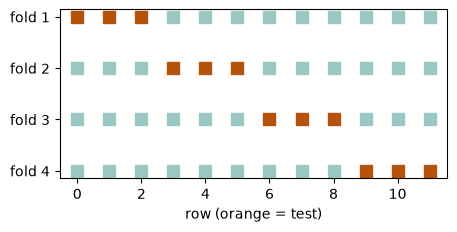

In [8]:
from sklearn.model_selection import KFold


def kfold_picture():
    n, k = 12, 4
    fig, ax = plt.subplots(figsize=(5, 2.2))
    for fold, (train, test) in enumerate(KFold(k).split(np.zeros((n, 1)))):
        ax.scatter(train, [fold] * len(train), marker="s", color="#99c9c2", s=80)
        ax.scatter(test, [fold] * len(test), marker="s", color="#b45309", s=80)
    ax.set_yticks(range(k), [f"fold {i + 1}" for i in range(k)])
    ax.set_xlabel("row (orange = test)")
    ax.invert_yaxis()


kfold_picture()

**✏️ Your turn:** you now have what you need for [Q16](#q16), [Q17](#q17), [Q18](#q18). Try one now, or carry on and do them in Part 3.

## Lesson 8: Which metric for which problem?

*Level: Advanced*

| Problem | Worst mistake | Focus on |
| --- | --- | --- |
| Cancer screening | missing a patient (FN) | recall, at acceptable precision |
| Spam filter | losing real email (FP) | precision |
| Fraud detection | both, with rare positives | PR-AUC, cost in money |
| Ranking leads for a sales team | a poor order | ROC AUC, precision at top k |
| Weather probability | wrong probabilities | log-loss, Brier score, calibration |
| Balanced image classes | any error | accuracy, macro F1 |
| House prices | typical error | MAE or RMSE in rupees |



#### Calibration



Of all cases given 80%, about 80% should turn out positive. A model can rank perfectly and still have wrong probabilities. A **calibration curve** shows this: a well-calibrated model follows the diagonal.



#### Choosing the score you report




- Agree on the metric **before** training.
- Translate it for the business: "catches 90% of fraud with 1 false alarm in 200".
- Report a spread, not just a mean: 0.82 ± 0.03 across folds.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

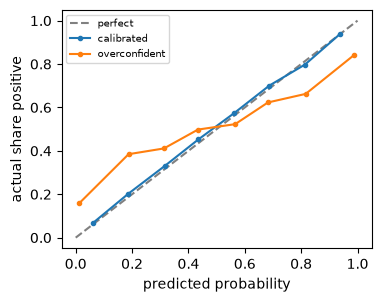

In [9]:
def calibration_demo():
    from sklearn.calibration import calibration_curve
    rng = np.random.default_rng(0)
    p_true = rng.uniform(0, 1, 4000)
    y = (rng.uniform(0, 1, 4000) < p_true).astype(int)
    overconfident = np.clip((p_true - 0.5) * 2 + 0.5, 0.001, 0.999)
    fig, ax = plt.subplots(figsize=(4, 3.1))
    ax.plot([0, 1], [0, 1], "--", color="gray", label="perfect")
    for name, p in [("calibrated", p_true), ("overconfident", overconfident)]:
        frac, mean_p = calibration_curve(y, p, n_bins=8)
        ax.plot(mean_p, frac, "o-", markersize=3, label=name)
    ax.set_xlabel("predicted probability")
    ax.set_ylabel("actual share positive")
    ax.legend(fontsize=7)


calibration_demo()

**✏️ Your turn:** you now have what you need for [Q7](#q7), [Q9](#q9), [Q20](#q20). Try one now, or carry on and do them in Part 3.

## Lesson 9: Choosing a validation strategy

*Level: Advanced*

Your validation must imitate how the model will be used. Otherwise the score is an illusion.



| Situation | Mistake | Use |
| --- | --- | --- |
| Rare class | a fold with no positives | StratifiedKFold |
| Many rows per patient | same patient in train and test | GroupKFold |
| Forecasting | training on the future | TimeSeriesSplit |
| Tiny data (under ~50 rows) | a noisy single split | repeated k-fold or leave-one-out |
| Tuning and also reporting | the best score is optimistic | nested CV or a separate test set |



#### Worked example: why groups matter



Suppose each patient has 10 scans. A random split puts scans of the same patient on both sides. The model recognises the patient, not the disease, and scores 98%. With patients kept whole it may drop to 70%, and **70% is the true number**.



#### How many folds?



5 or 10 is the usual choice. More folds give more training data per fold but take longer. Don't read much into small differences: if the fold scores vary by ±0.03, a gain of 0.005 is noise.

**▶ See it run.** Before you run this, predict what will happen. Then change a number and run it again.

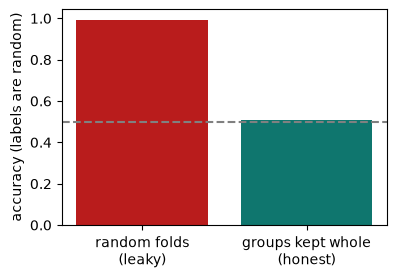

In [10]:
from sklearn.model_selection import KFold


def group_leak_demo():
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.model_selection import GroupKFold, cross_val_score
    rng = np.random.default_rng(0)
    groups = np.repeat(np.arange(30), 10)
    fingerprint = np.repeat(rng.normal(size=(30, 5)), 10, axis=0) + rng.normal(0, 0.1, (300, 5))
    y = np.repeat(rng.integers(0, 2, 30), 10)
    model = RandomForestClassifier(n_estimators=50, random_state=0)
    shuffled = cross_val_score(model, fingerprint, y, cv=KFold(5, shuffle=True, random_state=0)).mean()
    grouped = cross_val_score(model, fingerprint, y, cv=GroupKFold(5), groups=groups).mean()
    fig, ax = plt.subplots(figsize=(4.2, 2.8))
    ax.bar(["random folds\n(leaky)", "groups kept whole\n(honest)"], [shuffled, grouped], color=["#b91c1c", "#0f766e"])
    ax.axhline(0.5, ls="--", color="gray")
    ax.set_ylabel("accuracy (labels are random)")


group_leak_demo()

**✏️ Your turn:** you now have what you need for [Q16](#q16), [Q18](#q18), [Q17](#q17). Try one now, or carry on and do them in Part 3.

---
# Part 3: Practice like an interview

There are 20 questions here, easiest first.

**Work the way you would in a real interview:** restate the problem, try an example by hand, say the simple approach and its cost, improve it, then write the code. Test it with the cell. Only open an answer once you've made a real attempt, because struggling is where the learning happens.

**▶ Run this cell before the questions.** It sets up the data and tools they share.

In [11]:
from sklearn.metrics import (confusion_matrix, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             roc_curve, roc_auc_score, average_precision_score, matthews_corrcoef, cohen_kappa_score,
                             brier_score_loss, precision_recall_curve, precision_recall_fscore_support, top_k_accuracy_score, mean_squared_error)

from sklearn.model_selection import cross_val_score, KFold, LeaveOneOut, TimeSeriesSplit


<a id="q1"></a>
### Q1. Confusion Matrix

🟢 Warm-up · *Where the mistakes are*

Return [[TN, FP], [FN, TP]] for binary labels 0/1.

**Examples**

- `y = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0], y_pred = [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]` → `[[4, 1], [1, 4]]`
- `y = [0, 0, 1, 1], y_pred = [1, 1, 1, 1]` → `[[0, 2], [0, 2]]`

In [ ]:
def confusion(y, y_pred):
    """
    Return [[TN, FP], [FN, TP]] for binary labels 0/1.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(confusion, [
    (([1, 0, 1, 1, 0, 1, 0, 0, 1, 0], [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]), [[4, 1], [1, 4]]),
    (([0, 0, 1, 1], [1, 1, 1, 1]), [[0, 2], [0, 2]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count the four combinations of (actual, predicted).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`confusion_matrix(y, y_pred)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count the four combinations of (actual, predicted).

```python
def counts(y, p):
    tp = sum(1 for a, b in zip(y, p) if a == 1 and b == 1)
    fp = sum(1 for a, b in zip(y, p) if a == 0 and b == 1)
    fn = sum(1 for a, b in zip(y, p) if a == 1 and b == 0)
    tn = sum(1 for a, b in zip(y, p) if a == 0 and b == 0)
    return tp, fp, fn, tn


def confusion(y, y_pred):
    tp, fp, fn, tn = counts(y, y_pred)
    return [[tn, fp], [fn, tp]]
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `confusion_matrix(y, y_pred)`.

```python
def confusion(y, y_pred):
    return confusion_matrix(y, y_pred, labels=[0, 1])
```

**Cost:** O(n) time, O(k²) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count the four combinations of (actual, predicted). That costs O(n) time and O(1) space."

"I can do better: `confusion_matrix(y, y_pred)`. That's O(n) time and O(k²) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/confusion-matrix)

<a id="q2"></a>
### Q2. Precision

🟢 Warm-up · *Of the predicted positives, how many are right?*

Return TP / (TP + FP), rounded to 4 decimals.

**Examples**

- `y = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0], y_pred = [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]` → `0.8`
- `y = [1, 0, 0, 0], y_pred = [1, 1, 1, 0]` → `0.3333`

In [ ]:
def precision(y, y_pred):
    """
    Return TP / (TP + FP), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(precision, [
    (([1, 0, 1, 1, 0, 1, 0, 0, 1, 0], [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]), 0.8),
    (([1, 0, 0, 0], [1, 1, 1, 0]), 0.3333),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count TP and FP.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`precision_score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count TP and FP.

```python
def counts(y, p):
    tp = sum(1 for a, b in zip(y, p) if a == 1 and b == 1)
    fp = sum(1 for a, b in zip(y, p) if a == 0 and b == 1)
    fn = sum(1 for a, b in zip(y, p) if a == 1 and b == 0)
    tn = sum(1 for a, b in zip(y, p) if a == 0 and b == 0)
    return tp, fp, fn, tn


def precision(y, y_pred):
    tp, fp, fn, tn = counts(y, y_pred)
    return round(tp / (tp + fp), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `precision_score`.

```python
def precision(y, y_pred):
    return round(precision_score(y, y_pred), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count TP and FP. That costs O(n) time and O(1) space."

"I can do better: `precision_score`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/precision)

<a id="q3"></a>
### Q3. Recall

🟢 Warm-up · *Of the real positives, how many did we catch?*

Return TP / (TP + FN), rounded to 4 decimals.

**Examples**

- `y = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0], y_pred = [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]` → `0.8`
- `y = [1, 1, 1, 0], y_pred = [1, 0, 0, 0]` → `0.3333`

In [ ]:
def recall(y, y_pred):
    """
    Return TP / (TP + FN), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(recall, [
    (([1, 0, 1, 1, 0, 1, 0, 0, 1, 0], [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]), 0.8),
    (([1, 1, 1, 0], [1, 0, 0, 0]), 0.3333),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count TP and FN.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`recall_score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count TP and FN.

```python
def counts(y, p):
    tp = sum(1 for a, b in zip(y, p) if a == 1 and b == 1)
    fp = sum(1 for a, b in zip(y, p) if a == 0 and b == 1)
    fn = sum(1 for a, b in zip(y, p) if a == 1 and b == 0)
    tn = sum(1 for a, b in zip(y, p) if a == 0 and b == 0)
    return tp, fp, fn, tn


def recall(y, y_pred):
    tp, fp, fn, tn = counts(y, y_pred)
    return round(tp / (tp + fn), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `recall_score`.

```python
def recall(y, y_pred):
    return round(recall_score(y, y_pred), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count TP and FN. That costs O(n) time and O(1) space."

"I can do better: `recall_score`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/recall)

<a id="q4"></a>
### Q4. F1 Score

🟢 Warm-up · *Harmonic mean of precision and recall*

Return 2PR/(P + R), rounded to 4 decimals.

**Examples**

- `y = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0], y_pred = [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]` → `0.8`
- `y = [1, 1, 0, 0], y_pred = [1, 0, 1, 0]` → `0.5`

In [ ]:
def f1(y, y_pred):
    """
    Return 2PR/(P + R), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(f1, [
    (([1, 0, 1, 1, 0, 1, 0, 0, 1, 0], [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]), 0.8),
    (([1, 1, 0, 0], [1, 0, 1, 0]), 0.5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Precision and recall by hand, then the harmonic mean (= 2TP / (2TP + FP + FN)).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`f1_score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Precision and recall by hand, then the harmonic mean (= 2TP / (2TP + FP + FN)).

```python
def counts(y, p):
    tp = sum(1 for a, b in zip(y, p) if a == 1 and b == 1)
    fp = sum(1 for a, b in zip(y, p) if a == 0 and b == 1)
    fn = sum(1 for a, b in zip(y, p) if a == 1 and b == 0)
    tn = sum(1 for a, b in zip(y, p) if a == 0 and b == 0)
    return tp, fp, fn, tn


def f1(y, y_pred):
    tp, fp, fn, tn = counts(y, y_pred)
    return round(2 * tp / (2 * tp + fp + fn), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `f1_score`.

```python
def f1(y, y_pred):
    return round(f1_score(y, y_pred), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Precision and recall by hand, then the harmonic mean (= 2TP / (2TP + FP + FN)). That costs O(n) time and O(1) space."

"I can do better: `f1_score`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/f1-score)

<a id="q5"></a>
### Q5. Specificity

🟢 Warm-up · *True negative rate*

Return TN / (TN + FP), rounded to 4 decimals.

**Examples**

- `y = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0], y_pred = [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]` → `0.8`

In [ ]:
def specificity(y, y_pred):
    """
    Return TN / (TN + FP), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(specificity, [
    (([1, 0, 1, 1, 0, 1, 0, 0, 1, 0], [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]), 0.8),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count TN and FP.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

Recall of the negative class: `recall_score(y, y_pred, pos_label=0)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count TN and FP.

```python
def counts(y, p):
    tp = sum(1 for a, b in zip(y, p) if a == 1 and b == 1)
    fp = sum(1 for a, b in zip(y, p) if a == 0 and b == 1)
    fn = sum(1 for a, b in zip(y, p) if a == 1 and b == 0)
    tn = sum(1 for a, b in zip(y, p) if a == 0 and b == 0)
    return tp, fp, fn, tn


def specificity(y, y_pred):
    tp, fp, fn, tn = counts(y, y_pred)
    return round(tn / (tn + fp), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** Recall of the negative class: `recall_score(y, y_pred, pos_label=0)`.

```python
def specificity(y, y_pred):
    return round(recall_score(y, y_pred, pos_label=0), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count TN and FP. That costs O(n) time and O(1) space."

"I can do better: Recall of the negative class: `recall_score(y, y_pred, pos_label=0)`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/specificity)

<a id="q6"></a>
### Q6. Balanced Accuracy

🟢 Warm-up · *Average recall over classes*

Return the mean of each class's recall, rounded to 4 decimals — fair on imbalanced data.

**Examples**

- `y = [0, 0, 0, 0, 0, 0, 0, 0, 1, 1], y_pred = [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]` → `0.75`

In [ ]:
def balanced_accuracy(y, y_pred):
    """
    Return the mean of each class's recall, rounded to 4 decimals — fair on
    imbalanced data.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(balanced_accuracy, [
    (([0, 0, 0, 0, 0, 0, 0, 0, 1, 1], [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]), 0.75),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Recall of each class by counting, then average.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`balanced_accuracy_score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Recall of each class by counting, then average.

```python
def balanced_accuracy(y, y_pred):
    recalls = []
    for c in sorted(set(y)):
        total = sum(1 for a in y if a == c)
        hit = sum(1 for a, b in zip(y, y_pred) if a == c and b == c)
        recalls.append(hit / total)
    return round(sum(recalls) / len(recalls), 4)
```

**Cost:** O(n·k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `balanced_accuracy_score`.

```python
def balanced_accuracy(y, y_pred):
    return round(balanced_accuracy_score(y, y_pred), 4)
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Recall of each class by counting, then average. That costs O(n·k) time and O(k) space."

"I can do better: `balanced_accuracy_score`. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/balanced-accuracy)

<a id="q7"></a>
### Q7. Brier Score

🟢 Warm-up · *Squared error of probabilities*

Return the mean of (p − y)², rounded to 4 decimals. Lower = better calibrated.

**Examples**

- `y = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0], probs = [0.9, 0.1, 0.4, 0.8, 0.3, 0.7, 0.6, 0.2, 0.65, 0.35]` → `0.1245`

In [ ]:
def brier(y, probs):
    """
    Return the mean of (p − y)², rounded to 4 decimals. Lower = better
    calibrated.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(brier, [
    (([1, 0, 1, 1, 0, 1, 0, 0, 1, 0], [0.9, 0.1, 0.4, 0.8, 0.3, 0.7, 0.6, 0.2, 0.65, 0.35]), 0.1245),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop of squared differences.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`brier_score_loss`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop of squared differences.

```python
def brier(y, probs):
    return round(sum((p - a) ** 2 for a, p in zip(y, probs)) / len(y), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `brier_score_loss`.

```python
def brier(y, probs):
    return round(brier_score_loss(y, probs), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop of squared differences. That costs O(n) time and O(1) space."

"I can do better: `brier_score_loss`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/brier-score)

<a id="q8"></a>
### Q8. Top-k Accuracy

🟢 Warm-up · *Right answer among the top guesses*

Each row of scores ranks the classes 0, 1, 2…. Return the share of rows whose true class is among the k highest scores, rounded to 4 decimals.

**Examples**

- `y = [0, 1, 2, 2], scores = [[0.5, 0.3, 0.2], [0.4, 0.35, 0.25], [0.2, 0.5, 0.3], [0.6, 0.3, 0.1]], k = 2` → `0.75`

In [ ]:
def top_k(y, scores, k):
    """
    Each row of scores ranks the classes 0, 1, 2…. Return the share of rows
    whose true class is among the k highest scores, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(top_k, [
    (([0, 1, 2, 2], [[0.5, 0.3, 0.2], [0.4, 0.35, 0.25], [0.2, 0.5, 0.3], [0.6, 0.3, 0.1]], 2), 0.75),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort each row's classes by score and check the first k.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`top_k_accuracy_score(y, scores, k=k)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Sort each row's classes by score and check the first k.

```python
def top_k(y, scores, k):
    hits = 0
    for label, row in zip(y, scores):
        ranked = sorted(range(len(row)), key=lambda c: -row[c])
        if label in ranked[:k]:
            hits += 1
    return round(hits / len(y), 4)
```

**Cost:** O(n·k log k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `top_k_accuracy_score(y, scores, k=k)`.

```python
def top_k(y, scores, k):
    return round(top_k_accuracy_score(y, scores, k=k, labels=list(range(len(scores[0])))), 4)
```

**Cost:** O(n·k) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort each row's classes by score and check the first k. That costs O(n·k log k) time and O(k) space."

"I can do better: `top_k_accuracy_score(y, scores, k=k)`. That's O(n·k) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/top-k-accuracy)

<a id="q9"></a>
### Q9. Cost of Mistakes

🟢 Warm-up · *Business-aware evaluation*

A false positive costs fp\_cost and a false negative fn\_cost. Return the total cost of the predictions.

**Examples**

- `y = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0], y_pred = [1, 0, 0, 1, 0, 1, 1, 0, 1, 0], fp_cost = 1, fn_cost = 10` → `11`
- `y = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0], y_pred = [1, 1, 1, 1, 1, 1, 1, 1, 1, 1], fp_cost = 1, fn_cost = 10` → `5`

In [ ]:
def total_cost(y, y_pred, fp_cost, fn_cost):
    """
    A false positive costs fp_cost and a false negative fn_cost. Return the
    total cost of the predictions.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(total_cost, [
    (([1, 0, 1, 1, 0, 1, 0, 0, 1, 0], [1, 0, 0, 1, 0, 1, 1, 0, 1, 0], 1, 10), 11),
    (([1, 0, 1, 1, 0, 1, 0, 0, 1, 0], [1, 1, 1, 1, 1, 1, 1, 1, 1, 1], 1, 10), 5),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Count FP and FN by hand.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`confusion_matrix(...).ravel()` gives TN, FP, FN, TP.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Count FP and FN by hand.

```python
def counts(y, p):
    tp = sum(1 for a, b in zip(y, p) if a == 1 and b == 1)
    fp = sum(1 for a, b in zip(y, p) if a == 0 and b == 1)
    fn = sum(1 for a, b in zip(y, p) if a == 1 and b == 0)
    tn = sum(1 for a, b in zip(y, p) if a == 0 and b == 0)
    return tp, fp, fn, tn


def total_cost(y, y_pred, fp_cost, fn_cost):
    tp, fp, fn, tn = counts(y, y_pred)
    return fp * fp_cost + fn * fn_cost
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `confusion_matrix(...).ravel()` gives TN, FP, FN, TP.

```python
def total_cost(y, y_pred, fp_cost, fn_cost):
    tn, fp, fn, tp = confusion_matrix(y, y_pred, labels=[0, 1]).ravel()
    return int(fp * fp_cost + fn * fn_cost)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Count FP and FN by hand. That costs O(n) time and O(1) space."

"I can do better: `confusion_matrix(...).ravel()` gives TN, FP, FN, TP. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/cost-of-mistakes)

<a id="q10"></a>
### Q10. Macro vs Weighted F1

🟡 Interview standard · *Averaging over classes*

For multiclass labels return (macro F1, weighted F1), rounded to 4 decimals.

**Examples**

- `y = ['a', 'a', 'a', 'a', 'b', 'b', 'c'], y_pred = ['a', 'a', 'a', 'b', 'b', 'c', 'c']` → `(0.6746, 0.7279)`

In [ ]:
def macro_weighted_f1(y, y_pred):
    """
    For multiclass labels return (macro F1, weighted F1), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(macro_weighted_f1, [
    ((['a', 'a', 'a', 'a', 'b', 'b', 'c'], ['a', 'a', 'a', 'b', 'b', 'c', 'c']), (0.6746, 0.7279)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

F1 per class (one-vs-rest counts), then a plain average and a support-weighted average.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`f1_score(average='macro')` and `average='weighted'`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** F1 per class (one-vs-rest counts), then a plain average and a support-weighted average.

```python
def macro_weighted_f1(y, y_pred):
    classes = sorted(set(y) | set(y_pred))
    scores, supports = [], []
    for c in classes:
        tp = sum(1 for a, b in zip(y, y_pred) if a == c and b == c)
        fp = sum(1 for a, b in zip(y, y_pred) if a != c and b == c)
        fn = sum(1 for a, b in zip(y, y_pred) if a == c and b != c)
        scores.append(2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0)
        supports.append(sum(1 for a in y if a == c))
    macro = sum(scores) / len(scores)
    weighted = sum(s * n for s, n in zip(scores, supports)) / sum(supports)
    return (round(macro, 4), round(weighted, 4))
```

**Cost:** O(n·k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `f1_score(average='macro')` and `average='weighted'`.

```python
def macro_weighted_f1(y, y_pred):
    return (round(f1_score(y, y_pred, average="macro"), 4), round(f1_score(y, y_pred, average="weighted"), 4))
```

**Cost:** O(n·k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: F1 per class (one-vs-rest counts), then a plain average and a support-weighted average. That costs O(n·k) time and O(k) space."

"I can do better: `f1_score(average='macro')` and `average='weighted'`. That's O(n·k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/macro-vs-weighted-f1)

<a id="q11"></a>
### Q11. Per-Class Precision and Recall

🟡 Interview standard · *The classification report*

For each class (sorted), return (precision list, recall list), rounded to 4 decimals.

**Examples**

- `y = ['a', 'a', 'a', 'a', 'b', 'b', 'c'], y_pred = ['a', 'a', 'a', 'b', 'b', 'c', 'c']` → `([1.0, 0.5, 0.5], [0.75, 0.5, 1.0])`

In [ ]:
def per_class(y, y_pred):
    """
    For each class (sorted), return (precision list, recall list), rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(per_class, [
    ((['a', 'a', 'a', 'a', 'b', 'b', 'c'], ['a', 'a', 'a', 'b', 'b', 'c', 'c']), ([1.0, 0.5, 0.5], [0.75, 0.5, 1.0])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each class, count one-vs-rest TP, FP and FN.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`precision_recall_fscore_support(y, y_pred)` (what `classification_report` prints).

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** For each class, count one-vs-rest TP, FP and FN.

```python
def per_class(y, y_pred):
    precisions, recalls = [], []
    for c in sorted(set(y) | set(y_pred)):
        tp = sum(1 for a, b in zip(y, y_pred) if a == c and b == c)
        predicted = sum(1 for b in y_pred if b == c)
        actual = sum(1 for a in y if a == c)
        precisions.append(round(tp / predicted, 4) if predicted else 0.0)
        recalls.append(round(tp / actual, 4) if actual else 0.0)
    return (precisions, recalls)
```

**Cost:** O(n·k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `precision_recall_fscore_support(y, y_pred)` (what `classification_report` prints).

```python
def per_class(y, y_pred):
    p, r, _, _ = precision_recall_fscore_support(y, y_pred, zero_division=0)
    return (p.round(4), r.round(4))
```

**Cost:** O(n·k) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each class, count one-vs-rest TP, FP and FN. That costs O(n·k) time and O(k) space."

"I can do better: `precision_recall_fscore_support(y, y_pred)` (what `classification_report` prints). That's O(n·k) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/per-class-precision-and-recall)

<a id="q12"></a>
### Q12. ROC Curve Points

🟡 Interview standard · *Every threshold at once*

Using each distinct score as a threshold (highest first, predict 1 when score ≥ threshold), return (FPR list, TPR list), starting from (0, 0). Round to 4 decimals.

**Examples**

- `y = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0], scores = [0.9, 0.1, 0.4, 0.8, 0.3, 0.7, 0.6, 0.2, 0.65, 0.35]` → `([0.0, 0.0, 0.0, 0.0, 0.0, 0.2, 0.2, 0.4, 0.6, 0.8, 1.0], [0.0, 0.2, 0.4, 0.6, 0.8, 0.8, 1.0, 1.0, 1.0, 1.0, 1.0])`

In [ ]:
def roc_points(y, scores):
    """
    Using each distinct score as a threshold (highest first, predict 1 when
    score ≥ threshold), return (FPR list, TPR list), starting from (0, 0). Round
    to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(roc_points, [
    (([1, 0, 1, 1, 0, 1, 0, 0, 1, 0], [0.9, 0.1, 0.4, 0.8, 0.3, 0.7, 0.6, 0.2, 0.65, 0.35]), ([0.0, 0.0, 0.0, 0.0, 0.0, 0.2, 0.2, 0.4, 0.6, 0.8, 1.0], [0.0, 0.2, 0.4, 0.6, 0.8, 0.8, 1.0, 1.0, 1.0, 1.0, 1.0])),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Sort thresholds descending; at each, count TP and FP to get TPR and FPR.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`roc_curve(y, scores, drop_intermediate=False)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Sort thresholds descending; at each, count TP and FP to get TPR and FPR.

```python
def roc_points(y, scores):
    pos = sum(y)
    neg = len(y) - pos
    fpr, tpr = [0.0], [0.0]
    for t in sorted(set(scores), reverse=True):
        tp = sum(1 for a, s in zip(y, scores) if s >= t and a == 1)
        fp = sum(1 for a, s in zip(y, scores) if s >= t and a == 0)
        fpr.append(round(fp / neg, 4))
        tpr.append(round(tp / pos, 4))
    return (fpr, tpr)
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `roc_curve(y, scores, drop_intermediate=False)`.

```python
def roc_points(y, scores):
    fpr, tpr, _ = roc_curve(y, scores, drop_intermediate=False)
    return (fpr.round(4), tpr.round(4))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Sort thresholds descending; at each, count TP and FP to get TPR and FPR. That costs O(n²) time and O(n) space."

"I can do better: `roc_curve(y, scores, drop_intermediate=False)`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/roc-curve-points)

<a id="q13"></a>
### Q13. ROC AUC

🟡 Interview standard · *How well scores rank positives above negatives*

Return the area under the ROC curve, rounded to 4 decimals.

**Examples**

- `y = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0], scores = [0.9, 0.1, 0.4, 0.8, 0.3, 0.7, 0.6, 0.2, 0.65, 0.35]` → `0.96`
- `y = [0, 0, 1, 1], scores = [0.1, 0.4, 0.35, 0.8]` → `0.75`

In [ ]:
def auc(y, scores):
    """
    Return the area under the ROC curve, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(auc, [
    (([1, 0, 1, 1, 0, 1, 0, 0, 1, 0], [0.9, 0.1, 0.4, 0.8, 0.3, 0.7, 0.6, 0.2, 0.65, 0.35]), 0.96),
    (([0, 0, 1, 1], [0.1, 0.4, 0.35, 0.8]), 0.75),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

AUC = probability a random positive scores higher than a random negative: compare every pair (ties count ½).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`roc_auc_score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** AUC = probability a random positive scores higher than a random negative: compare every pair (ties count ½).

```python
def auc(y, scores):
    pos = [s for a, s in zip(y, scores) if a == 1]
    neg = [s for a, s in zip(y, scores) if a == 0]
    wins = 0.0
    for p in pos:
        for n in neg:
            wins += 1 if p > n else 0.5 if p == n else 0
    return round(wins / (len(pos) * len(neg)), 4)
```

**Cost:** O(n²) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `roc_auc_score`.

```python
def auc(y, scores):
    return round(roc_auc_score(y, scores), 4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: AUC = probability a random positive scores higher than a random negative: compare every pair (ties count ½). That costs O(n²) time and O(1) space."

"I can do better: `roc_auc_score`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/roc-auc)

<a id="q14"></a>
### Q14. Matthews Correlation Coefficient

🟡 Interview standard · *One balanced number*

Return MCC = (TP·TN − FP·FN) / √((TP+FP)(TP+FN)(TN+FP)(TN+FN)), rounded to 4 decimals.

**Examples**

- `y = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0], y_pred = [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]` → `0.6`
- `y = [1, 1, 1, 1, 0], y_pred = [1, 1, 1, 1, 1]` → `0.0`

In [ ]:
import math

def mcc(y, y_pred):
    """
    Return MCC = (TP·TN − FP·FN) / √((TP+FP)(TP+FN)(TN+FP)(TN+FN)), rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(mcc, [
    (([1, 0, 1, 1, 0, 1, 0, 0, 1, 0], [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]), 0.6),
    (([1, 1, 1, 1, 0], [1, 1, 1, 1, 1]), 0.0),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Confusion counts, then the formula (0 if the denominator is 0).

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`matthews_corrcoef`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Confusion counts, then the formula (0 if the denominator is 0).

```python
def counts(y, p):
    tp = sum(1 for a, b in zip(y, p) if a == 1 and b == 1)
    fp = sum(1 for a, b in zip(y, p) if a == 0 and b == 1)
    fn = sum(1 for a, b in zip(y, p) if a == 1 and b == 0)
    tn = sum(1 for a, b in zip(y, p) if a == 0 and b == 0)
    return tp, fp, fn, tn


def mcc(y, y_pred):
    tp, fp, fn, tn = counts(y, y_pred)
    den = math.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    return round((tp * tn - fp * fn) / den, 4) if den else 0.0
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `matthews_corrcoef`.

```python
def mcc(y, y_pred):
    return round(matthews_corrcoef(y, y_pred), 4)
```

**Cost:** O(n) time, O(1) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Confusion counts, then the formula (0 if the denominator is 0). That costs O(n) time and O(1) space."

"I can do better: `matthews_corrcoef`. That's O(n) time and O(1) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/matthews-correlation-coefficient)

<a id="q15"></a>
### Q15. Cohen's Kappa

🟡 Interview standard · *Agreement beyond chance*

Return κ = (p\_o − p\_e)/(1 − p\_e) between two label lists, rounded to 4 decimals.

**Examples**

- `a = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0], b = [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]` → `0.6`
- `a = ['yes', 'yes', 'no', 'no', 'yes'], b = ['yes', 'no', 'no', 'no', 'yes']` → `0.6154`

In [ ]:
def kappa(a, b):
    """
    Return κ = (p_o − p_e)/(1 − p_e) between two label lists, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(kappa, [
    (([1, 0, 1, 1, 0, 1, 0, 0, 1, 0], [1, 0, 0, 1, 0, 1, 1, 0, 1, 0]), 0.6),
    ((['yes', 'yes', 'no', 'no', 'yes'], ['yes', 'no', 'no', 'no', 'yes']), 0.6154),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Observed agreement, and chance agreement from each rater's class shares.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`cohen_kappa_score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Observed agreement, and chance agreement from each rater's class shares.

```python
def kappa(a, b):
    n = len(a)
    p_o = sum(1 for x, y in zip(a, b) if x == y) / n
    p_e = sum((a.count(c) / n) * (b.count(c) / n) for c in set(a) | set(b))
    return round((p_o - p_e) / (1 - p_e), 4)
```

**Cost:** O(n·k) time, O(k) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `cohen_kappa_score`.

```python
def kappa(a, b):
    return round(cohen_kappa_score(a, b), 4)
```

**Cost:** O(n) time, O(k) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Observed agreement, and chance agreement from each rater's class shares. That costs O(n·k) time and O(k) space."

"I can do better: `cohen_kappa_score`. That's O(n) time and O(k) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/cohens-kappa)

<a id="q16"></a>
### Q16. Cross-Validated R²

🟡 Interview standard · *Score on every fold*

Run 3-fold cross-validation (in order, no shuffling) of a straight-line fit and return the R² of each fold, rounded to 4 decimals.

**Examples**

- `x = [1, 2, 3, 4, 5, 6, 7, 8, 9], y = [2.1, 3.9, 6.2, 7.8, 10.1, 12.2, 13.8, 16.1, 18.0]` → `[0.9875, 0.9901, 0.9854]`

In [ ]:
from sklearn.linear_model import LinearRegression

def cv_r2(x, y):
    """
    Run 3-fold cross-validation (in order, no shuffling) of a straight-line fit
    and return the R² of each fold, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(cv_r2, [
    (([1, 2, 3, 4, 5, 6, 7, 8, 9], [2.1, 3.9, 6.2, 7.8, 10.1, 12.2, 13.8, 16.1, 18.0]), [0.9875, 0.9901, 0.9854]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

For each fold: fit slope/intercept on the other rows, predict the fold, compute R².

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`cross_val_score(LinearRegression(), X, y, cv=KFold(3))`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** For each fold: fit slope/intercept on the other rows, predict the fold, compute R².

```python
def cv_r2(x, y):
    n, k = len(x), 3
    scores = []
    for f in range(k):
        test = list(range(f * n // k, (f + 1) * n // k))
        train = [i for i in range(n) if i not in test]
        tx, ty = [x[i] for i in train], [y[i] for i in train]
        mx, my = sum(tx) / len(tx), sum(ty) / len(ty)
        slope = sum((a - mx) * (b - my) for a, b in zip(tx, ty)) / sum((a - mx) ** 2 for a in tx)
        pred = [my + slope * (x[i] - mx) for i in test]
        actual = [y[i] for i in test]
        mean = sum(actual) / len(actual)
        r2 = 1 - sum((a - p) ** 2 for a, p in zip(actual, pred)) / sum((a - mean) ** 2 for a in actual)
        scores.append(round(r2, 4))
    return scores
```

**Cost:** O(k·n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `cross_val_score(LinearRegression(), X, y, cv=KFold(3))`.

```python
def cv_r2(x, y):
    return cross_val_score(LinearRegression(), np.array(x).reshape(-1, 1), y, cv=KFold(3)).round(4)
```

**Cost:** O(k·n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: For each fold: fit slope/intercept on the other rows, predict the fold, compute R². That costs O(k·n) time and O(n) space."

"I can do better: `cross_val_score(LinearRegression(), X, y, cv=KFold(3))`. That's O(k·n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/cross-validated-r)

<a id="q17"></a>
### Q17. Leave-One-Out Error

🟡 Interview standard · *n folds of size 1*

Leave each point out in turn, predict it with the mean of the others, and return the average squared error, rounded to 4 decimals.

**Examples**

- `y = [3, 5, 7, 9]` → `8.8889`

In [ ]:
from sklearn.dummy import DummyRegressor

def loo_error(y):
    """
    Leave each point out in turn, predict it with the mean of the others, and
    return the average squared error, rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(loo_error, [
    (([3, 5, 7, 9],), 8.8889),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over points: mean of the rest, squared error.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`cross_val_score(DummyRegressor(), X, y, cv=LeaveOneOut(), scoring='neg_mean_squared_error')`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop over points: mean of the rest, squared error.

```python
def loo_error(y):
    total = 0
    for i in range(len(y)):
        rest = y[:i] + y[i + 1:]
        guess = sum(rest) / len(rest)
        total += (y[i] - guess) ** 2
    return round(total / len(y), 4)
```

**Cost:** O(n²) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `cross_val_score(DummyRegressor(), X, y, cv=LeaveOneOut(), scoring='neg_mean_squared_error')`.

```python
def loo_error(y):
    X = np.zeros((len(y), 1))
    scores = cross_val_score(DummyRegressor(), X, y, cv=LeaveOneOut(), scoring="neg_mean_squared_error")
    return round(-scores.mean(), 4)
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over points: mean of the rest, squared error. That costs O(n²) time and O(1) space."

"I can do better: `cross_val_score(DummyRegressor(), X, y, cv=LeaveOneOut(), scoring='neg_mean_squared_error')`. That's O(n²) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/leave-one-out-error)

<a id="q18"></a>
### Q18. Time-Series Splits

🟡 Interview standard · *Never train on the future*

Return the test indices of each split of TimeSeriesSplit(n\_splits) on n time-ordered rows: each test block has n // (n\_splits + 1) rows and comes after its training rows.

**Examples**

- `n = 10, n_splits = 3` → `[[4, 5], [6, 7], [8, 9]]`
- `n = 12, n_splits = 2` → `[[4, 5, 6, 7], [8, 9, 10, 11]]`

In [ ]:
def ts_splits(n, n_splits):
    """
    Return the test indices of each split of TimeSeriesSplit(n_splits) on n
    time-ordered rows: each test block has n // (n_splits + 1) rows and comes
    after its training rows.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(ts_splits, [
    ((10, 3), [[4, 5], [6, 7], [8, 9]]),
    ((12, 2), [[4, 5, 6, 7], [8, 9, 10, 11]]),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Test size = n // (splits + 1); the last split ends at n; walk backwards.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`TimeSeriesSplit(n_splits)`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Test size = n // (splits + 1); the last split ends at n; walk backwards.

```python
def ts_splits(n, n_splits):
    size = n // (n_splits + 1)
    out = []
    for i in range(n_splits):
        end = n - (n_splits - 1 - i) * size
        out.append(list(range(end - size, end)))
    return out
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `TimeSeriesSplit(n_splits)`.

```python
def ts_splits(n, n_splits):
    return [test.tolist() for _, test in TimeSeriesSplit(n_splits=n_splits).split(np.zeros((n, 1)))]
```

**Cost:** O(n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Test size = n // (splits + 1); the last split ends at n; walk backwards. That costs O(n) time and O(n) space."

"I can do better: `TimeSeriesSplit(n_splits)`. That's O(n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/time-series-splits)

<a id="q19"></a>
### Q19. Average Precision (PR AUC)

🔴 Stretch · *Area under precision–recall*

Return Σ (Rₙ − Rₙ₋₁)·Pₙ over thresholds from high to low, rounded to 4 decimals.

**Examples**

- `y = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0], scores = [0.9, 0.1, 0.4, 0.8, 0.3, 0.7, 0.6, 0.2, 0.65, 0.35]` → `0.9667`
- `y = [0, 0, 1, 1], scores = [0.1, 0.4, 0.35, 0.8]` → `0.8333`

In [ ]:
def average_precision(y, scores):
    """
    Return Σ (Rₙ − Rₙ₋₁)·Pₙ over thresholds from high to low, rounded to 4
    decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(average_precision, [
    (([1, 0, 1, 1, 0, 1, 0, 0, 1, 0], [0.9, 0.1, 0.4, 0.8, 0.3, 0.7, 0.6, 0.2, 0.65, 0.35]), 0.9667),
    (([0, 0, 1, 1], [0.1, 0.4, 0.35, 0.8]), 0.8333),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Walk down the sorted scores, updating precision and recall at each threshold; add recall gain × precision.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`average_precision_score`.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Walk down the sorted scores, updating precision and recall at each threshold; add recall gain × precision.

```python
def average_precision(y, scores):
    pos = sum(y)
    ap, prev_recall = 0.0, 0.0
    for t in sorted(set(scores), reverse=True):
        tp = sum(1 for a, s in zip(y, scores) if s >= t and a == 1)
        fp = sum(1 for a, s in zip(y, scores) if s >= t and a == 0)
        rec = tp / pos
        ap += (rec - prev_recall) * tp / (tp + fp)
        prev_recall = rec
    return round(ap, 4)
```

**Cost:** O(n²) time, O(n) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `average_precision_score`.

```python
def average_precision(y, scores):
    return round(average_precision_score(y, scores), 4)
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Walk down the sorted scores, updating precision and recall at each threshold; add recall gain × precision. That costs O(n²) time and O(n) space."

"I can do better: `average_precision_score`. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/average-precision-pr-auc)

<a id="q20"></a>
### Q20. Best Threshold for F1

🔴 Stretch · *Tuning the cut-off*

Try every distinct score as the threshold (predict 1 when score ≥ t) and return (best t, its F1), rounded to 4 decimals.

**Examples**

- `y = [1, 0, 1, 1, 0, 1, 0, 0, 1, 0], scores = [0.9, 0.1, 0.4, 0.8, 0.3, 0.7, 0.6, 0.2, 0.65, 0.35]` → `(0.4, 0.9091)`

In [ ]:
def best_threshold(y, scores):
    """
    Try every distinct score as the threshold (predict 1 when score ≥ t) and
    return (best t, its F1), rounded to 4 decimals.
    """
    # Write your code here
    pass


# ▶ Run this cell to test your answer
check(best_threshold, [
    (([1, 0, 1, 1, 0, 1, 0, 0, 1, 0], [0.9, 0.1, 0.4, 0.8, 0.3, 0.7, 0.6, 0.2, 0.65, 0.35]), (0.4, 0.9091)),
])

<details>
<summary><b>💡 Hint 1: a way in</b></summary>

Loop over thresholds, compute F1 each time, keep the best.

</details>

<details>
<summary><b>💡 Hint 2: the better idea</b></summary>

`precision_recall_curve` gives precision and recall at every threshold; compute F1 for all at once.

</details>

<details>
<summary><b>✅ Answer: From scratch — plain Python & NumPy</b></summary>

**Idea:** Loop over thresholds, compute F1 each time, keep the best.

```python
def best_threshold(y, scores):
    best = (None, -1)
    for t in sorted(set(scores)):
        tp = sum(1 for a, s in zip(y, scores) if s >= t and a == 1)
        fp = sum(1 for a, s in zip(y, scores) if s >= t and a == 0)
        fn = sum(1 for a, s in zip(y, scores) if s < t and a == 1)
        f = 2 * tp / (2 * tp + fp + fn)
        if f > best[1]:
            best = (t, f)
    return (round(best[0], 4), round(best[1], 4))
```

**Cost:** O(n²) time, O(1) space

</details>

<details>
<summary><b>✅ Answer: With scikit-learn</b></summary>

**Idea:** `precision_recall_curve` gives precision and recall at every threshold; compute F1 for all at once.

```python
def best_threshold(y, scores):
    prec, rec, thr = precision_recall_curve(y, scores)
    f1s = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    i = int(np.argmax(f1s))
    return (round(thr[i], 4), round(f1s[i], 4))
```

**Cost:** O(n log n) time, O(n) space

</details>

<details>
<summary><b>🎤 How to explain it out loud</b></summary>

"My first thought is: Loop over thresholds, compute F1 each time, keep the best. That costs O(n²) time and O(1) space."

"I can do better: `precision_recall_curve` gives precision and recall at every threshold; compute F1 for all at once. That's O(n log n) time and O(n) space."

</details>

[▶ Watch both answers run line by line](https://abpandey-dev.github.io/learn-python-from-scratch-to-advanced/ml/#/q/evaluation/best-threshold-for-f1)

---
# Part 4: Interview questions, out loud

Cover the answer, **say yours out loud**, then open it and compare. Aim for two or three clear sentences, then an example.

<details>
<summary><b>1. Precision vs recall?</b></summary>

Precision: of the items flagged positive, the share that truly are. Recall: of the truly positive items, the share that were flagged. Raising the threshold usually increases precision and decreases recall.

</details>

<details>
<summary><b>2. Why is accuracy misleading for imbalanced data?</b></summary>

If 99% of transactions are legitimate, predicting 'legitimate' always gives 99% accuracy while catching zero fraud. Use recall, precision, F1, PR-AUC, balanced accuracy or MCC.

</details>

<details>
<summary><b>3. What does ROC AUC mean?</b></summary>

The probability that the model scores a randomly chosen positive higher than a randomly chosen negative. 0.5 is random, 1.0 is perfect ranking.

</details>

<details>
<summary><b>4. ROC AUC vs PR AUC?</b></summary>

ROC AUC can look high on heavily imbalanced data because the many true negatives keep the false positive rate low. PR AUC focuses on the positive class and is more informative when positives are rare.

</details>

<details>
<summary><b>5. Why use cross-validation?</b></summary>

It uses all data for both training and evaluation, gives a more stable estimate than a single split, and shows variability across folds.

</details>

<details>
<summary><b>6. What is the difference between validation and test sets?</b></summary>

The validation set (or CV) guides choices — model, features, hyper-parameters. The test set is held back for one final, unbiased estimate after all choices are made.

</details>


---
# Check yourself before moving on

You're ready for the next notebook when you can tick these **without looking**:

- [ ] I can explain: The confusion matrix
- [ ] I can explain: A full worked example: screening 1,000 people
- [ ] I can explain: Precision, recall and F1
- [ ] I can explain: ROC and precision–recall curves
- [ ] I can explain: Why F1 uses the harmonic mean, and macro vs weighted
- [ ] I can explain: ROC and PR curves, by hand
- [ ] I can explain: Cross-validation done right
- [ ] I can explain: Which metric for which problem?
- [ ] I can explain: Choosing a validation strategy

**Revision drill.** Come back in a few days, set a 25-minute timer per question, and solve these from a blank cell:

- [ ] [Q16](#q16) Cross-Validated R²
- [ ] [Q17](#q17) Leave-One-Out Error
- [ ] [Q18](#q18) Time-Series Splits
- [ ] [Q19](#q19) Average Precision (PR AUC)
- [ ] [Q20](#q20) Best Threshold for F1

Spaced repetition beats re-reading: redoing a question after you've partly forgotten it is what makes it stick.